# Week 4 - Linear Regression

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import statsmodels.formula.api as smf

In [9]:
obs = pd.read_csv('55_Hare_Data_2012.txt')

In [10]:
obs.head()

,date,time,grid,trap,l_ear,r_ear,sex,age,weight,hindft,notes,b_key,session_id,study
0,11/26/1998,NaN,bonrip,1A,414D096A08,NaN,NaN,NaN,1370.0,160.0,NaN,917.0,51,Population
1,11/26/1998,NaN,bonrip,2C,414D320671,NaN,M,NaN,1430.0,NaN,NaN,936.0,51,Population
2,11/26/1998,NaN,bonrip,2D,414D103E3A,NaN,M,NaN,1430.0,NaN,NaN,921.0,51,Population
3,11/26/1998,NaN,bonrip,2E,414D262D43,NaN,NaN,NaN,1490.0,135.0,NaN,931.0,51,Population
4,11/26/1998,NaN,bonrip,3B,414D2B4B58,NaN,NaN,NaN,1710.0,150.0,NaN,933.0,51,Population


In [11]:
obs.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3380 entries, 0 to 3379
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date        3380 non-null   object 
 1   time        264 non-null    object 
 2   grid        3380 non-null   object 
 3   trap        3368 non-null   object 
 4   l_ear       3332 non-null   object 
 5   r_ear       3211 non-null   object 
 6   sex         3028 non-null   object 
 7   age         1269 non-null   object 
 8   weight      2845 non-null   float64
 9   hindft      1633 non-null   float64
 10  notes       243 non-null    object 
 11  b_key       3333 non-null   float64
 12  session_id  3380 non-null   int64  
 13  study       3217 non-null   object 
dtypes: float64(3), int64(1), object(10)
memory usage: 369.8+ KB


In [12]:
obs['date'] = pd.to_datetime(obs['date'])
print(obs['date'].dtype)

datetime64[ns]


### Examine the hare's age data

In [13]:
obs['age'].value_counts(dropna=False)

age
NaN          2111
A             564
J             267
a             183
j             128
1/2/2013       21
1/4/2013       21
3/4/2013       18
1              12
U              11
?              10
a 3/4 yr.       4
2 yrs.          3
u               3
A 3/4           2
1.5             2
3.5 yrs.        2
2.25 yrs        2
1 yr.           2
1 yr            2
a 1 yr.         2
A 1.5           1
2.5 yrs         1
3 yrs.          1
a 2 yrs.        1
J 3/4           1
2 yrs           1
A 1/2           1
a 1 yr          1
1.25            1
3.25 yrs.       1
Name: count, dtype: int64

When you make a decision, document it.

We will keep all hares with a j as juvenile, and all hares with a as an adult.

In [17]:
# Update age values to juvenile and adult for observations where 'a' and 'j' are included
obs.loc[obs['age'].str.contains('j', case=False, na=False), 'age'] = 'juvenile'
obs.loc[obs['age'].str.contains('a', case=False, na=False), 'age'] = 'adult'

# Filter for confirmed observations of juvenile and adult hares
obs_juv_adult = obs[obs['age'].isin(['juvenile', 'adult'])].copy()
print('Number of juvenile and adult hare observations (captures):', len(obs_juv_adult))

Number of juvenile and adult hare observations (captures): 1155


In [19]:
# Extract year in which each observation happened
obs_juv_adult['year'] = obs_juv_adult['date'].dt.year

In [20]:
obs_juv_adult.head()

,date,time,grid,trap,l_ear,r_ear,sex,age,weight,hindft,notes,b_key,session_id,study,year
108,1999-06-23,NaN,bonrip,2C,68,69,M,juvenile,395.0,126.0,NaN,643.0,53,Population,1999
109,1999-06-23,NaN,bonrip,2E,70,71,F,juvenile,420.0,137.0,NaN,653.0,53,Population,1999
110,1999-06-23,NaN,bonrip,3D,72,73,M,juvenile,445.0,144.0,NaN,944.0,53,Population,1999
111,1999-06-23,NaN,bonrip,4B,76,77,M,juvenile,410.0,115.0,NaN,663.0,53,Population,1999
112,1999-06-23,NaN,bonrip,4C,78,79,M,juvenile,430.0,132.0,NaN,670.0,53,Population,1999


In [23]:
# Count observations per year and age, then move age values into columns

obs_per_year = obs_juv_adult.groupby(['year', 'age']).size().unstack()
obs_per_year

age,adult,juvenile
year,,
1999,150.0,126.0
2000,159.0,67.0
2001,72.0,22.0
2002,3.0,NaN
2003,1.0,18.0
2004,NaN,8.0
2005,95.0,48.0
2006,101.0,15.0
2007,13.0,5.0


In [24]:
obs_per_year.index

Index([1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010,
       2011, 2012],
      dtype='int32', name='year')

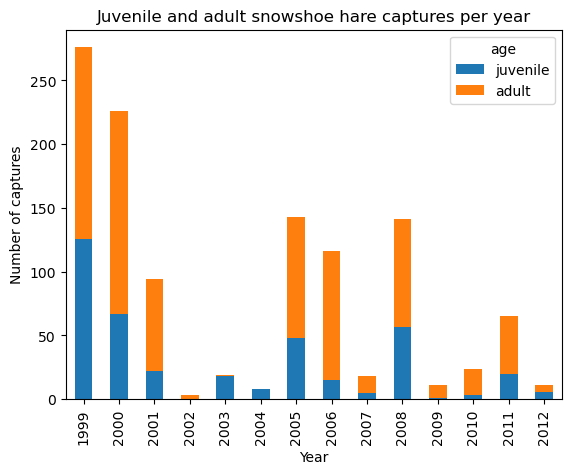

In [26]:
obs_per_year[['juvenile', 'adult']].plot(kind='bar',
                                         stacked=True,
                                         title='Juvenile and adult snowshoe hare captures per year',
                                         xlabel='Year',
                                         ylabel='Number of captures');

### Plotting with `matplotlib`

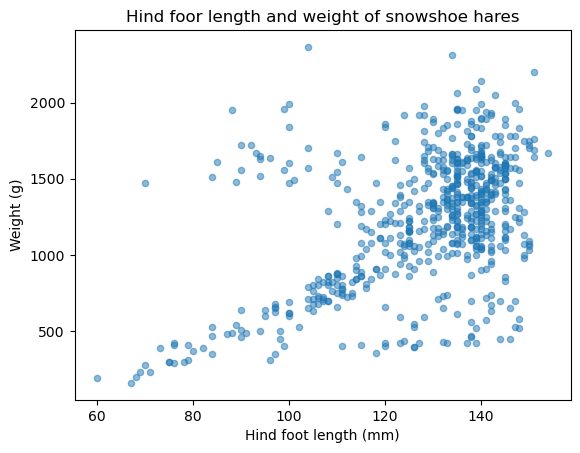

In [ ]:
# Initialize empty figure (fig) and axes (ax)
fig, ax = plt.subplots()

# Add scatter plot of hares data to our figure's axes
obs_juv_adult.plot(kind='scatter', x='hindft', y='weight', ax=ax, alpha=0.5)

# Update axes
ax.set_title('Hind foot length and weight of snowshoe hares')
ax.set_xlabel('Hind foot length (mm)')
ax.set_ylabel('Weight (g)')

# Display
plt.show()

### Linear regression

For our analysis, we want to investigate possible relations between hind foot length and weight for juvenile hares.

In [34]:
juv_w_hft = obs_juv_adult[obs_juv_adult['age'] == 'juvenile'].dropna(subset=['hindft', 'weight'])



Number of observations: 265


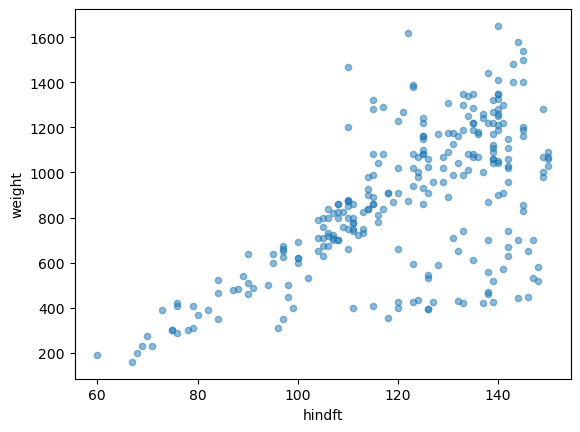

In [37]:
print('Number of observations:', len(juv_w_hft))
juv_w_hft.plot.scatter(x='hindft', y='weight', alpha=0.5);

In [ ]:
# Fit model: weight explained by hind foot length
model = smf.ols('weight ~ hindft', data=juv_w_hft).fit() # fits the model to the data

In [41]:
model.params

Intercept   -352.771986
hindft        10.092240
dtype: float64

In [43]:
# Retrieve parameters
intercept = model.params['Intercept']
print('y-intercept:', intercept)

slope = model.params['hindft']
print('slope:', slope)

y-intercept: -352.77198564640645
slope: 10.092239638623006


In [44]:
print('R^2:', model.rsquared)

R^2: 0.3871164783665738


R^2 is the coefficient of determination. It is between 0 and 1. R^2=1 is a perfect fit model to the data. 

We interpret it as the proportion of variance in the response that is explained by the least sqaures lines with the predictor variable.

In [53]:
# Smallest and largest hind foot lengths
x_start = juv_w_hft['hindft'].min()
x_end = juv_w_hft['hindft'].max()

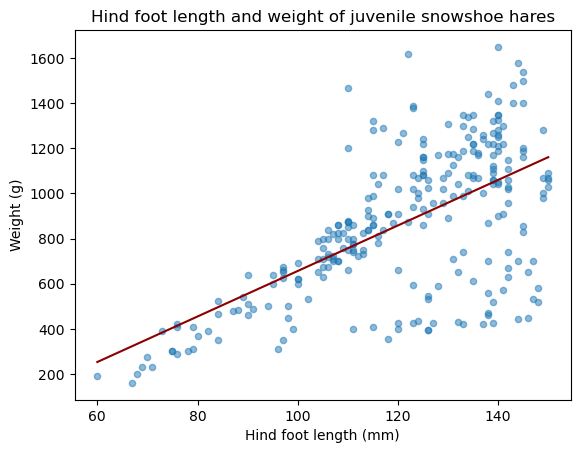

In [56]:
# Initialize empty figure (fig) and axes (ax)
fig, ax = plt.subplots()

# Add scatter plot of hares data to our figure's axes
juv_w_hft.plot(kind='scatter', x='hindft', y='weight', ax=ax, alpha=0.5)

# Add regression line to axes
ax.plot([x_start, x_end], 
        [intercept + slope * x_start, intercept + slope * x_end],
        color='darkred')

# Update axes
ax.set_title('Hind foot length and weight of juvenile snowshoe hares')
ax.set_xlabel('Hind foot length (mm)')
ax.set_ylabel('Weight (g)')

# Display
plt.show()